# Cross-Sensor Global Models — SF Bay Traffic

**Companion notebook** to the Stage 1 univariate work (sensor 0 only).  
Goal: train **one shared MLP** and **one shared CNN** on many sensors, then evaluate on **held-out sensors** the model never trained on.

**Run order (Colab):** Runtime → Run all. GPU is optional; CPU is fine for the default subsample.

**What this notebook does before modelling**
1. Sensor quality audit (variance, near-constant series)
2. Occupancy-level heterogeneity (do sensors share one scale?)
3. Autocorrelation at lags 1 / 24 / 168 across many sensors (lookback choice)
4. Cross-sensor correlation sample (is a shared model plausible?)
5. Only then: stratified train / held-out sensor split, windowing, MLP, CNN

## 0 — Colab setup

In [ ]:
import sys, subprocess

def ensure(packages):
    import importlib
    missing = []
    for p, mod in packages:
        try:
            importlib.import_module(mod)
        except ImportError:
            missing.append(p)
    if missing:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

ensure([
    ("numpy", "numpy"),
    ("pandas", "pandas"),
    ("matplotlib", "matplotlib"),
    ("scikit-learn", "sklearn"),
    ("tensorflow", "tensorflow"),
])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from time import perf_counter

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
print("Ready.")

Ready.


## 1 — Load dataset

Same source as the group project: hourly occupancy at 862 SF Bay Area freeway sensors  
([multivariate-time-series-data / traffic](https://github.com/laiguokun/multivariate-time-series-data#traffic-usage)).

No timestamps or sensor locations — columns are positional IDs only.

In [ ]:
DATA_URL = (
    "https://raw.githubusercontent.com/laiguokun/multivariate-time-series-data/"
    "master/traffic/traffic.txt.gz"
)
DATA_PATH = Path("traffic.txt.gz")

if not DATA_PATH.exists():
    import urllib.request
    print("Downloading traffic.txt.gz …")
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)
    print("Saved", DATA_PATH.resolve())
else:
    print("Using cached", DATA_PATH.resolve())

df = pd.read_csv(DATA_PATH, header=None)
print(f"Shape: {df.shape[0]} hours × {df.shape[1]} sensors")
print(f"Nominal days: {df.shape[0] / 24:.1f}")
display(df.iloc[:3, :5])

Using cached /content/traffic.txt.gz
Shape: 17544 hours × 862 sensors
Nominal days: 731.0


,0,1,2,3,4
0,0.0048,0.0146,0.0289,0.0142,0.0064
1,0.0072,0.0148,0.0350,0.0174,0.0084
2,0.0040,0.0101,0.0267,0.0124,0.0049


## 2 — Sensor quality audit

**Decide:** which sensors are usable for a global model?

Near-constant or tiny-variance sensors teach nothing transferable and can dominate MSE after scaling. We score each sensor on training-time stats only (first 60% of hours) so selection does not peek at later periods.

Usable sensors: 862 / 862
Dropped: 0


,count
usable,
True,862


,sensor,train_mean,train_std,train_min,train_max,n_unique,missing,range,usable


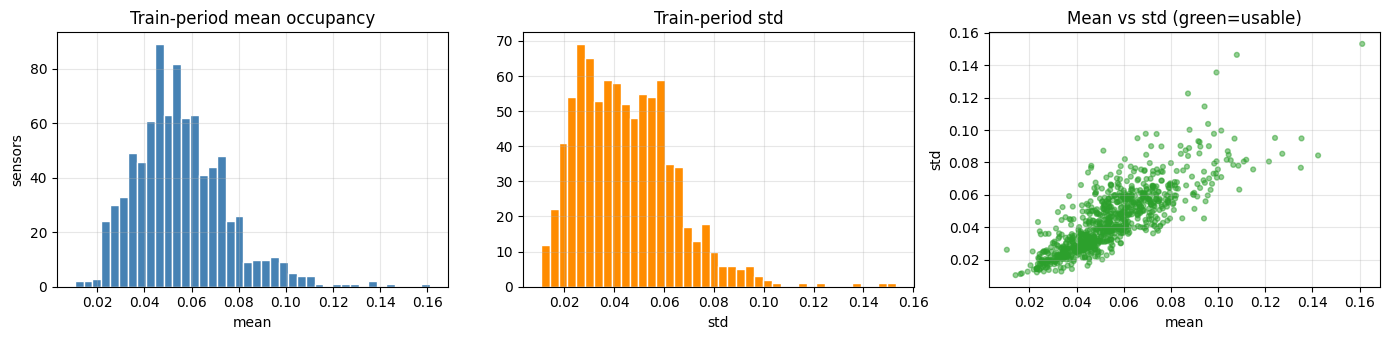

In [ ]:
TRAIN_FRAC = 0.60
VAL_FRAC = 0.20  # remaining 20% = test time (reserved in this notebook too)
N_HOURS = len(df)
train_end = int(TRAIN_FRAC * N_HOURS)
val_end = int((TRAIN_FRAC + VAL_FRAC) * N_HOURS)

train_block = df.iloc[:train_end]

sensor_stats = pd.DataFrame({
    "sensor": np.arange(df.shape[1]),
    "train_mean": train_block.mean().to_numpy(),
    "train_std": train_block.std(ddof=0).to_numpy(),
    "train_min": train_block.min().to_numpy(),
    "train_max": train_block.max().to_numpy(),
    "n_unique": train_block.nunique().to_numpy(),
    "missing": train_block.isna().sum().to_numpy(),
})
sensor_stats["range"] = sensor_stats["train_max"] - sensor_stats["train_min"]

# Hard quality gates (tune only if audit plots disagree)
MIN_STD = 1e-3
MIN_UNIQUE = 20

sensor_stats["usable"] = (
    (sensor_stats["missing"] == 0)
    & (sensor_stats["train_std"] >= MIN_STD)
    & (sensor_stats["n_unique"] >= MIN_UNIQUE)
    & (sensor_stats["train_min"] >= 0)
    & (sensor_stats["train_max"] <= 1)
)

usable = sensor_stats.loc[sensor_stats["usable"], "sensor"].to_numpy()
print(f"Usable sensors: {len(usable)} / {df.shape[1]}")
print(f"Dropped: {df.shape[1] - len(usable)}")
display(sensor_stats["usable"].value_counts().rename("count").to_frame())
display(sensor_stats.loc[~sensor_stats["usable"]].head(10))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].hist(sensor_stats["train_mean"], bins=40, color="steelblue", edgecolor="white")
axes[0].set(title="Train-period mean occupancy", xlabel="mean", ylabel="sensors")
axes[1].hist(sensor_stats["train_std"], bins=40, color="darkorange", edgecolor="white")
axes[1].set(title="Train-period std", xlabel="std")
axes[2].scatter(
    sensor_stats["train_mean"], sensor_stats["train_std"],
    c=sensor_stats["usable"].map({True: "tab:green", False: "tab:red"}),
    s=12, alpha=0.5,
)
axes[2].set(title="Mean vs std (green=usable)", xlabel="mean", ylabel="std")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Audit interpretation (read the plots)

- If means spread widely across sensors, a **single global scaler** would squash quiet sensors and stretch busy ones — prefer **per-sensor standardization** fit on each sensor’s training period only.
- If many sensors fail the variance / uniqueness gates, drop them; do not force a “global” model on dead loops.

## 3 — Temporal structure across sensors

**Decide:** is lookback **168** (one week) justified beyond sensor 0?

Compute Pearson autocorrelation at lags 1, 24, and 168 on the training block for a large sample of usable sensors.

,count,mean,std,min,25%,50%,75%,max
sensor,120.0,420.633333,233.044156,2.000000,223.750000,423.000000,598.500000,857.000000
acf_lag1,120.0,0.835486,0.061108,0.659908,0.803123,0.847106,0.874589,0.940824
acf_lag24,120.0,0.734390,0.084190,0.435628,0.697202,0.739499,0.790088,0.909610
acf_lag168,120.0,0.807383,0.088275,0.498382,0.774171,0.824914,0.858932,0.991717


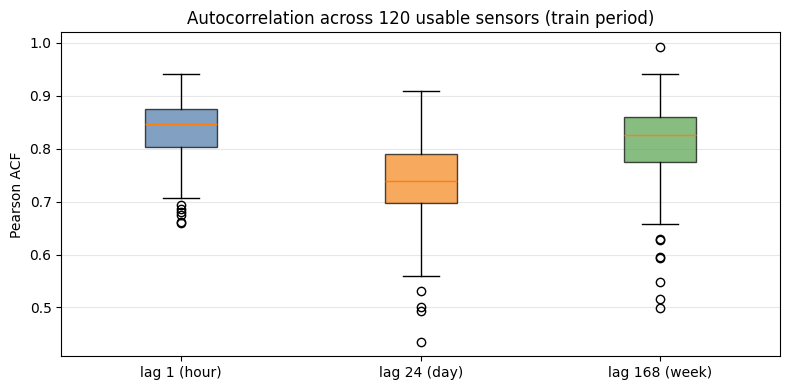

Median ACFs:
 acf_lag1      0.847106
acf_lag24     0.739499
acf_lag168    0.824914
dtype: float64

Selected LOOKBACK = 168 hours | HORIZON = 1 hour
Rule: prefer weekly lookback when median ACF@168 >= median ACF@24 across the sensor sample.


In [ ]:
RNG = np.random.default_rng(401003)
ACF_SAMPLE = min(120, len(usable))
acf_sensors = np.sort(RNG.choice(usable, size=ACF_SAMPLE, replace=False))

def acf_at_lag(x, lag):
    x = np.asarray(x, dtype=float)
    if x.std() < 1e-12:
        return np.nan
    return pd.Series(x).autocorr(lag=lag)

acf_rows = []
for s in acf_sensors:
    x = train_block[s].to_numpy()
    acf_rows.append({
        "sensor": int(s),
        "acf_lag1": acf_at_lag(x, 1),
        "acf_lag24": acf_at_lag(x, 24),
        "acf_lag168": acf_at_lag(x, 168),
    })
acf_df = pd.DataFrame(acf_rows)
display(acf_df.describe().T)

fig, ax = plt.subplots(figsize=(8, 4))
parts = ax.boxplot(
    [acf_df["acf_lag1"].dropna(), acf_df["acf_lag24"].dropna(), acf_df["acf_lag168"].dropna()],
    tick_labels=["lag 1 (hour)", "lag 24 (day)", "lag 168 (week)"],
    patch_artist=True,
)
for patch, color in zip(parts["boxes"], ["#4C78A8", "#F58518", "#54A24B"]):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax.set(title=f"Autocorrelation across {ACF_SAMPLE} usable sensors (train period)", ylabel="Pearson ACF")
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

median_lags = acf_df[["acf_lag1", "acf_lag24", "acf_lag168"]].median()
print("Median ACFs:\n", median_lags)
# Decision rule used below
LOOKBACK = 168 if median_lags["acf_lag168"] >= median_lags["acf_lag24"] else 24
HORIZON = 1
print(f"\nSelected LOOKBACK = {LOOKBACK} hours | HORIZON = {HORIZON} hour")
print("Rule: prefer weekly lookback when median ACF@168 >= median ACF@24 across the sensor sample.")

## 4 — Cross-sensor similarity

**Decide:** is a shared weight set plausible, or are sensors so dissimilar that transfer is hopeless?

Pairwise correlation on a subsample of usable sensors (train period). High typical correlation → shared daily/weekly shape; very low → expect weak zero-shot transfer and rely more on pooling diversity + per-sensor scaling.

Pairwise correlations among 80 sensors:
count    3160.000000
mean        0.597230
std         0.183354
min         0.024403
10%         0.322881
25%         0.483432
50%         0.625340
75%         0.736804
90%         0.816811
max         0.987542
dtype: float64


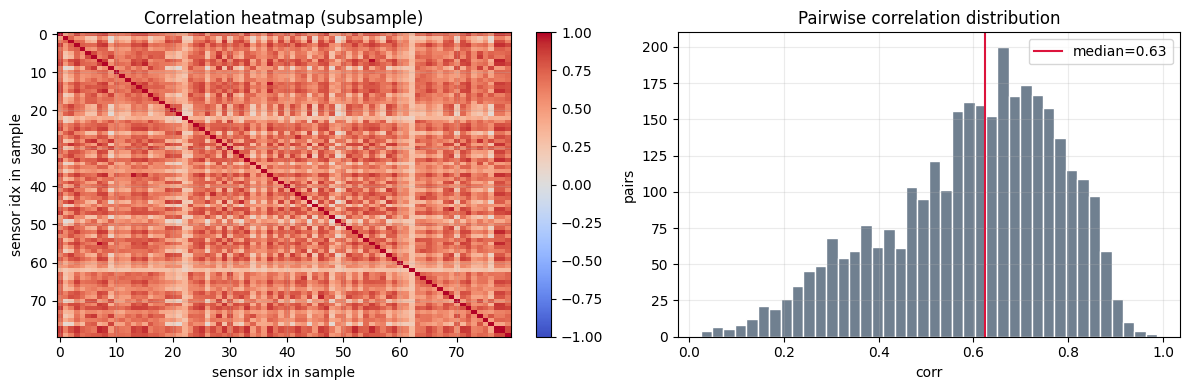

Transfer expectation: moderate-to-strong shared structure — global model is justified


In [ ]:
CORR_SAMPLE = min(80, len(usable))
corr_sensors = np.sort(RNG.choice(usable, size=CORR_SAMPLE, replace=False))
corr_mat = train_block[corr_sensors].corr()
# Upper triangle only
iu = np.triu_indices_from(corr_mat.to_numpy(), k=1)
pair_corr = corr_mat.to_numpy()[iu]

print(f"Pairwise correlations among {CORR_SAMPLE} sensors:")
print(pd.Series(pair_corr).describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
im = axes[0].imshow(corr_mat, vmin=-1, vmax=1, cmap="coolwarm", aspect="auto")
axes[0].set(title="Correlation heatmap (subsample)", xlabel="sensor idx in sample", ylabel="sensor idx in sample")
plt.colorbar(im, ax=axes[0], fraction=0.046)
axes[1].hist(pair_corr, bins=40, color="slategray", edgecolor="white")
axes[1].axvline(np.median(pair_corr), color="crimson", label=f"median={np.median(pair_corr):.2f}")
axes[1].set(title="Pairwise correlation distribution", xlabel="corr", ylabel="pairs")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

median_corr = float(np.median(pair_corr))
if median_corr >= 0.4:
    transfer_expectation = "moderate-to-strong shared structure — global model is justified"
elif median_corr >= 0.2:
    transfer_expectation = "weak-to-moderate shared structure — global model may help but expect a gap vs specialists"
else:
    transfer_expectation = "weak shared structure — treat cross-sensor results cautiously"
print("Transfer expectation:", transfer_expectation)

## 5 — Design decisions (locked from analysis)

These defaults follow the audits above. Edit only if your plots disagree.

In [ ]:
# --- Modelling contract (analysis-informed) ---
# LOOKBACK / HORIZON already set in Section 3

# Per-sensor scaling: occupancy levels differ widely (Section 2).
SCALE_MODE = "per_sensor"  # do not switch to "global" without re-checking mean/std spread

# Stratify held-out sensors by train-period mean occupancy so the test pool is not only easy/quiet loops.
N_TRAIN_SENSORS = 80   # Colab-friendly; raise toward len(usable) if you have time
N_HELD_OUT_SENSORS = 25
MAX_TRAIN_WINDOWS = 80_000  # subsample pooled windows if needed
SEED = 401003

assert SCALE_MODE == "per_sensor"
assert LOOKBACK in (24, 168)
assert N_TRAIN_SENSORS + N_HELD_OUT_SENSORS <= len(usable), "Reduce N_* or relax quality gates"

print({
    "LOOKBACK": LOOKBACK,
    "HORIZON": HORIZON,
    "SCALE_MODE": SCALE_MODE,
    "N_TRAIN_SENSORS": N_TRAIN_SENSORS,
    "N_HELD_OUT_SENSORS": N_HELD_OUT_SENSORS,
    "MAX_TRAIN_WINDOWS": MAX_TRAIN_WINDOWS,
    "time_split": (train_end, val_end, N_HOURS),
    "transfer_expectation": transfer_expectation,
})

{'LOOKBACK': 168, 'HORIZON': 1, 'SCALE_MODE': 'per_sensor', 'N_TRAIN_SENSORS': 80, 'N_HELD_OUT_SENSORS': 25, 'MAX_TRAIN_WINDOWS': 80000, 'time_split': (10526, 14035, 17544), 'transfer_expectation': 'moderate-to-strong shared structure — global model is justified'}


## 6 — Stratified sensor split

Held-out sensors are drawn across occupancy quintiles (train-period mean).  
Same calendar/time indices for everyone; **no sensor in the held-out set contributes training windows**.

In [ ]:
usable_stats = sensor_stats.loc[sensor_stats["usable"]].copy()
usable_stats["occ_bin"] = pd.qcut(usable_stats["train_mean"], q=5, labels=False, duplicates="drop")

rng = np.random.default_rng(SEED)
held_out = []
train_sensors = []

for _, grp in usable_stats.groupby("occ_bin"):
    ids = grp["sensor"].to_numpy().copy()
    rng.shuffle(ids)
    # Proportional held-out take from each bin
    n_hold = max(1, int(round(N_HELD_OUT_SENSORS * len(ids) / len(usable_stats))))
    n_hold = min(n_hold, max(1, len(ids) // 5))  # leave most for train pool
    held_out.extend(ids[:n_hold].tolist())
    train_sensors.extend(ids[n_hold:].tolist())

held_out = np.array(sorted(set(held_out)), dtype=int)
train_pool = np.array(sorted(set(train_sensors) - set(held_out)), dtype=int)

# Cap train sensor count for runtime
if len(train_pool) > N_TRAIN_SENSORS:
    train_sensors = np.sort(rng.choice(train_pool, size=N_TRAIN_SENSORS, replace=False))
else:
    train_sensors = train_pool

# Cap / pad held-out to target size while keeping stratification as much as possible
if len(held_out) > N_HELD_OUT_SENSORS:
    held_out = np.sort(rng.choice(held_out, size=N_HELD_OUT_SENSORS, replace=False))
elif len(held_out) < N_HELD_OUT_SENSORS:
    extra = np.setdiff1d(train_pool, train_sensors)
    need = N_HELD_OUT_SENSORS - len(held_out)
    if len(extra) >= need:
        held_out = np.sort(np.concatenate([held_out, rng.choice(extra, size=need, replace=False)]))

# Ensure disjoint
assert len(np.intersect1d(train_sensors, held_out)) == 0

split_summary = pd.DataFrame({
    "role": ["train_sensors", "held_out_sensors"],
    "count": [len(train_sensors), len(held_out)],
    "mean_of_means": [
        sensor_stats.set_index("sensor").loc[train_sensors, "train_mean"].mean(),
        sensor_stats.set_index("sensor").loc[held_out, "train_mean"].mean(),
    ],
    "mean_of_stds": [
        sensor_stats.set_index("sensor").loc[train_sensors, "train_std"].mean(),
        sensor_stats.set_index("sensor").loc[held_out, "train_std"].mean(),
    ],
})
display(split_summary)
print("Held-out sensors:", held_out.tolist())
print("Train sensors (first 20):", train_sensors[:20].tolist(), "…")


,role,count,mean_of_means,mean_of_stds
0,train_sensors,80,0.055202,0.046893
1,held_out_sensors,25,0.054075,0.039150


Held-out sensors: [43, 57, 94, 174, 175, 207, 214, 219, 298, 313, 457, 561, 606, 618, 650, 686, 691, 694, 739, 741, 748, 780, 781, 788, 839]
Train sensors (first 20): [2, 6, 24, 27, 63, 74, 102, 134, 144, 145, 146, 155, 167, 195, 200, 204, 206, 210, 233, 238] …


## 7 — Per-sensor scaling, chronological windows, pooling

For each sensor \(s\):

1. Fit mean/std on **train hours only** for that sensor  
2. Build supervised windows inside each time block (train / val / test)  
3. Pool windows across **train sensors** for fitting  
4. Score on **held-out sensors** (validation hours for model selection; test hours reserved)

Windows never cross time-block boundaries. Targets stay in original occupancy units for MAE/RMSE after inverse transform.

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def fit_sensor_scaler(series_train):
    mu = float(np.mean(series_train))
    sigma = float(np.std(series_train))
    if sigma < 1e-8:
        sigma = 1.0
    return mu, sigma

def transform(x, mu, sigma):
    return (x - mu) / sigma

def inverse_transform(x, mu, sigma):
    return x * sigma + mu

def make_windows(values, lookback):
    values = np.asarray(values, dtype=np.float32)
    n = len(values) - lookback
    if n <= 0:
        return np.empty((0, lookback), np.float32), np.empty((0,), np.float32)
    shape = (n, lookback)
    strides = (values.strides[0], values.strides[0])
    X = np.lib.stride_tricks.as_strided(values, shape=shape, strides=strides).copy()
    y = values[lookback:].copy()
    return X, y

def build_sensor_windows(sensor_id, lookback=LOOKBACK):
    raw = df[sensor_id].to_numpy(dtype=np.float64)
    tr = raw[:train_end]
    va = raw[train_end:val_end]
    te = raw[val_end:]
    mu, sigma = fit_sensor_scaler(tr)
    tr_s = transform(tr, mu, sigma)
    va_s = transform(va, mu, sigma)
    te_s = transform(te, mu, sigma)
    Xtr, ytr = make_windows(tr_s, lookback)
    Xva, yva = make_windows(va_s, lookback)
    Xte, yte = make_windows(te_s, lookback)
    ytr_raw = tr[lookback:lookback + len(ytr)]
    yva_raw = va[lookback:lookback + len(yva)]
    yte_raw = te[lookback:lookback + len(yte)]
    return {
        "sensor": sensor_id,
        "mu": mu,
        "sigma": sigma,
        "X_train": Xtr, "y_train": ytr, "y_train_raw": ytr_raw.astype(np.float32),
        "X_val": Xva, "y_val": yva, "y_val_raw": yva_raw.astype(np.float32),
        "X_test": Xte, "y_test": yte, "y_test_raw": yte_raw.astype(np.float32),
    }

print("Building windows for train sensors …")
train_packs = [build_sensor_windows(int(s)) for s in train_sensors]
print("Building windows for held-out sensors …")
held_packs = [build_sensor_windows(int(s)) for s in held_out]

X_train = np.concatenate([p["X_train"] for p in train_packs], axis=0)
y_train = np.concatenate([p["y_train"] for p in train_packs], axis=0)
X_val_train_sensors = np.concatenate([p["X_val"] for p in train_packs], axis=0)
y_val_train_sensors = np.concatenate([p["y_val"] for p in train_packs], axis=0)
y_val_train_sensors_raw = np.concatenate([p["y_val_raw"] for p in train_packs], axis=0)

rng = np.random.default_rng(SEED)
if len(X_train) > MAX_TRAIN_WINDOWS:
    idx = rng.choice(len(X_train), size=MAX_TRAIN_WINDOWS, replace=False)
    X_train, y_train = X_train[idx], y_train[idx]
    print(f"Subsampled training windows to {MAX_TRAIN_WINDOWS}")

X_val_held = np.concatenate([p["X_val"] for p in held_packs], axis=0)
y_val_held = np.concatenate([p["y_val"] for p in held_packs], axis=0)
y_val_held_raw = np.concatenate([p["y_val_raw"] for p in held_packs], axis=0)

shapes = pd.DataFrame([
    {"set": "train (pooled train sensors)", "X": X_train.shape, "y": y_train.shape},
    {"set": "val (train sensors)", "X": X_val_train_sensors.shape, "y": y_val_train_sensors.shape},
    {"set": "val (held-out sensors)", "X": X_val_held.shape, "y": y_val_held.shape},
])
display(shapes)
print(f"Lookback={LOOKBACK} → MLP/CNN input length {LOOKBACK}")


Building windows for train sensors …
Building windows for held-out sensors …
Subsampled training windows to 80000


,set,X,y
0,train (pooled train sensors),"(80000, 168)","(80000,)"
1,val (train sensors),"(267280, 168)","(267280,)"
2,val (held-out sensors),"(83525, 168)","(83525,)"


Lookback=168 → MLP/CNN input length 168


## 8 — Baselines on held-out sensors

Same baselines as Stage 1, evaluated on **held-out sensors / validation hours** — the bar a global network must clear for transfer.

In [ ]:
def persistence_pred(packs, split="val"):
    rows = []
    for p in packs:
        Xb = p[f"X_{split}"]
        y_raw = p[f"y_{split}_raw"]
        if len(Xb) == 0:
            continue
        pred_scaled = Xb[:, -1]
        pred = inverse_transform(pred_scaled, p["mu"], p["sigma"])
        rows.append((y_raw, pred))
    y = np.concatenate([r[0] for r in rows])
    pred = np.concatenate([r[1] for r in rows])
    return y, pred

def weekly_naive_pred(packs, split="val"):
    rows = []
    for p in packs:
        Xb = p[f"X_{split}"]
        y_raw = p[f"y_{split}_raw"]
        if len(Xb) == 0:
            continue
        if LOOKBACK >= 168:
            pred_scaled = Xb[:, -168]
            pred = inverse_transform(pred_scaled, p["mu"], p["sigma"])
        else:
            pred = inverse_transform(Xb[:, 0], p["mu"], p["sigma"])
        rows.append((y_raw, pred))
    y = np.concatenate([r[0] for r in rows])
    pred = np.concatenate([r[1] for r in rows])
    return y, pred

def metrics(y, pred, name):
    return {
        "Model": name,
        "MAE": mean_absolute_error(y, pred),
        "RMSE": mean_squared_error(y, pred) ** 0.5,
    }

y_h, pred_p = persistence_pred(held_packs, "val")
y_h2, pred_w = weekly_naive_pred(held_packs, "val")
assert np.allclose(y_h, y_h2)

baseline_table = pd.DataFrame([
    metrics(y_h, pred_p, "Persistence (held-out val)"),
    metrics(y_h, pred_w, "Weekly seasonal naive (held-out val)"),
])
display(baseline_table)
best_baseline_rmse = baseline_table["RMSE"].min()
print(f"Best baseline RMSE on held-out val: {best_baseline_rmse:.5f}")

,Model,MAE,RMSE
0,Persistence (held-out val),0.012639,0.024846
1,Weekly seasonal naive (held-out val),0.010564,0.027648


Best baseline RMSE on held-out val: 0.02485


## 9 — Global MLP

One network shared across train sensors. Input: flattened length-`LOOKBACK` history (per-sensor standardized).  
Early stopping monitors **train-sensor validation** loss (tuning signal). Transfer is judged on **held-out sensors**.

In [ ]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Conv1D, MaxPooling1D, Flatten, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__)

def score_packs(model, packs, split="val", cnn=False):
    rows_y, rows_p = [], []
    for p in packs:
        Xb = p[f"X_{split}"]
        if len(Xb) == 0:
            continue
        Xin = Xb[..., None] if cnn else Xb
        pred_scaled = model.predict(Xin, verbose=0).ravel()
        pred = inverse_transform(pred_scaled, p["mu"], p["sigma"])
        rows_y.append(p[f"y_{split}_raw"])
        rows_p.append(pred.astype(np.float32))
    y = np.concatenate(rows_y)
    pred = np.concatenate(rows_p)
    return metrics(y, pred, "tmp"), y, pred

EPOCHS = 40
PATIENCE = 5
BATCH = 64
LR = 1e-3

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
mlp = Sequential([
    Input(shape=(LOOKBACK,)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(1),
])
mlp.compile(optimizer=Adam(LR), loss="mse")
mlp.summary()

rng = np.random.default_rng(SEED)
if len(X_val_train_sensors) > 30_000:
    vidx = rng.choice(len(X_val_train_sensors), size=30_000, replace=False)
    X_es, y_es = X_val_train_sensors[vidx], y_val_train_sensors[vidx]
else:
    X_es, y_es = X_val_train_sensors, y_val_train_sensors

t0 = perf_counter()
mlp_hist = mlp.fit(
    X_train, y_train,
    validation_data=(X_es, y_es),
    epochs=EPOCHS,
    batch_size=BATCH,
    shuffle=True,  # cross-sensor pool: shuffle OK within train-time windows
    callbacks=[EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)],
    verbose=1,
)
mlp_time = perf_counter() - t0
print(f"MLP training time: {mlp_time:.1f}s | epochs run: {len(mlp_hist.history['loss'])}")

mlp_held_metrics, _, _ = score_packs(mlp, held_packs, "val", cnn=False)
mlp_held_metrics["Model"] = "Global MLP (held-out val)"
mlp_held_metrics["Params"] = mlp.count_params()
mlp_held_metrics["Train seconds"] = mlp_time
display(pd.DataFrame([mlp_held_metrics]))

TensorFlow 2.21.0


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        10,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,929 (50.50 KB)

 Trainable params: 12,929 (50.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.1991 - val_loss: 0.1773
Epoch 2/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.1535 - val_loss: 0.1701
Epoch 3/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.1435 - val_loss: 0.1640
Epoch 4/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.1378 - val_loss: 0.1562
Epoch 5/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.1334 - val_loss: 0.1531
Epoch 6/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.1299 - val_loss: 0.1524
Epoch 7/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.1270 - val_loss: 0.1512
Epoch 8/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.1242 - val_loss: 0.1490
Epoch 9/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.1218 - val_loss: 0.1501
Epoch 10/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.1192 - val_loss: 0.1511
Epoch 11/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.1162 - val_loss: 0.1521
Epoch 12/40
1250/1250 ━━━━━━━━

,Model,MAE,RMSE,Params,Train seconds
0,Global MLP (held-out val),0.008289,0.017476,12929,32.008276


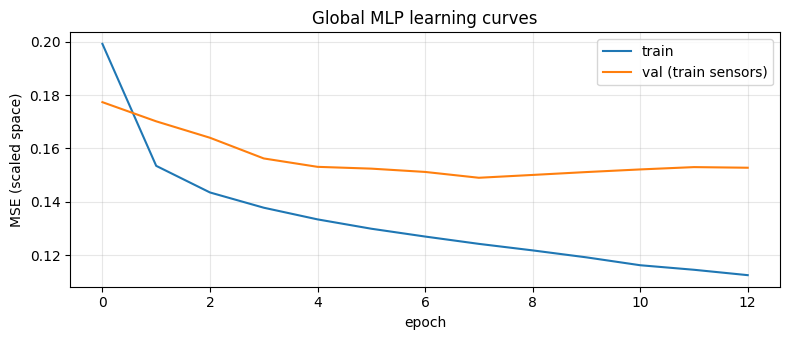

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(mlp_hist.history["loss"], label="train")
ax.plot(mlp_hist.history["val_loss"], label="val (train sensors)")
ax.set(title="Global MLP learning curves", xlabel="epoch", ylabel="MSE (scaled space)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 10 — Global CNN

Same pooled windows, reshaped to `(lookback, 1)`. Conv filters should pick up local rush-hour shapes that recur across sensors after per-sensor scaling.

In [ ]:
X_train_cnn = X_train[..., None]
X_es_cnn = X_es[..., None]

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
cnn = Sequential([
    Input(shape=(LOOKBACK, 1)),
    Conv1D(16, kernel_size=7, activation="relu", padding="same"),
    MaxPooling1D(2),
    Conv1D(32, kernel_size=5, activation="relu", padding="same"),
    MaxPooling1D(2),
    Flatten(),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(1),
])
cnn.compile(optimizer=Adam(LR), loss="mse")
cnn.summary()

t0 = perf_counter()
cnn_hist = cnn.fit(
    X_train_cnn, y_train,
    validation_data=(X_es_cnn, y_es),
    epochs=EPOCHS,
    batch_size=BATCH,
    shuffle=True,
    callbacks=[EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)],
    verbose=1,
)
cnn_time = perf_counter() - t0
print(f"CNN training time: {cnn_time:.1f}s | epochs run: {len(cnn_hist.history['loss'])}")

cnn_held_metrics, _, _ = score_packs(cnn, held_packs, "val", cnn=True)
cnn_held_metrics["Model"] = "Global CNN (held-out val)"
cnn_held_metrics["Params"] = cnn.count_params()
cnn_held_metrics["Train seconds"] = cnn_time
display(pd.DataFrame([cnn_held_metrics]))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 168, 16)        │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 84, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 84, 32)         │         2,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 42, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1344)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        43,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 45,793 (178.88 KB)

 Trainable params: 45,793 (178.88 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 14s 11ms/step - loss: 0.2153 - val_loss: 0.1620
Epoch 2/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - loss: 0.1697 - val_loss: 0.1513
Epoch 3/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 14s 11ms/step - loss: 0.1627 - val_loss: 0.1487
Epoch 4/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - loss: 0.1575 - val_loss: 0.1516
Epoch 5/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 21s 10ms/step - loss: 0.1539 - val_loss: 0.1512
Epoch 6/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 14s 11ms/step - loss: 0.1529 - val_loss: 0.1517
Epoch 7/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 14s 11ms/step - loss: 0.1502 - val_loss: 0.1546
Epoch 8/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - loss: 0.1482 - val_loss: 0.1505
CNN training time: 114.6s | epochs run: 8


,Model,MAE,RMSE,Params,Train seconds
0,Global CNN (held-out val),0.008159,0.017302,45793,114.594131


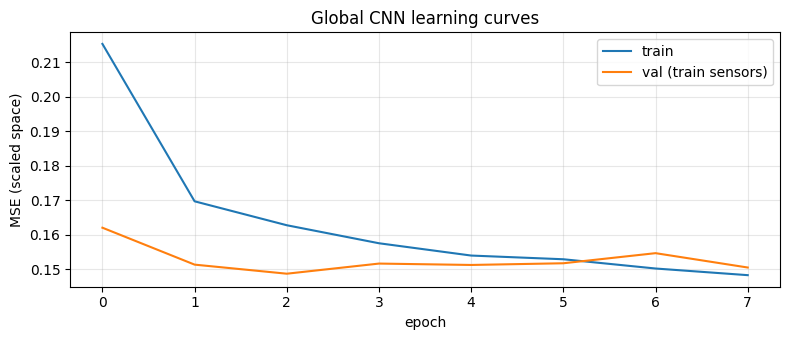

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(cnn_hist.history["loss"], label="train")
ax.plot(cnn_hist.history["val_loss"], label="val (train sensors)")
ax.set(title="Global CNN learning curves", xlabel="epoch", ylabel="MSE (scaled space)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 11 — Comparison on held-out sensors

Primary question: does a model trained on other sensors beat simple baselines **on sensors it never saw**?

,Model,MAE,RMSE,Params,Train seconds,RMSE improvement vs best baseline (%)
0,Global CNN (held-out val),0.008159,0.017302,45793,114.594131,30.362497
1,Global MLP (held-out val),0.008289,0.017476,12929,32.008276,29.661621
2,Persistence (held-out val),0.012639,0.024846,0,0.000000,0.000000
3,Weekly seasonal naive (held-out val),0.010564,0.027648,0,0.000000,-11.278116


,sensor,Global CNN RMSE,Persistence RMSE,Weekly naive RMSE,train_mean,beats_best_baseline
12,606,0.005086,0.011877,0.007790,0.031188,True
3,174,0.005511,0.010312,0.013990,0.025547,True
2,94,0.007340,0.013411,0.012685,0.021368,True
18,739,0.008562,0.015794,0.013777,0.044397,True
17,694,0.008586,0.012742,0.013905,0.036105,True
6,214,0.009149,0.011670,0.014226,0.045390,True
13,618,0.011381,0.018710,0.016818,0.042008,True
4,175,0.011498,0.020342,0.018770,0.043694,True
22,781,0.011666,0.016964,0.018942,0.060058,True
10,457,0.012112,0.017409,0.015361,0.074757,True


Global CNN beats best baseline on 100% of held-out sensors


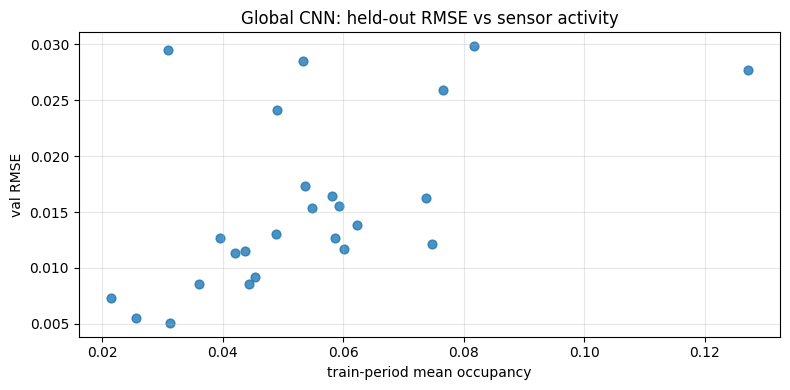

In [ ]:
comparison = pd.DataFrame([
    {**baseline_table.iloc[0].to_dict(), "Params": 0, "Train seconds": 0.0},
    {**baseline_table.iloc[1].to_dict(), "Params": 0, "Train seconds": 0.0},
    mlp_held_metrics,
    cnn_held_metrics,
])
comparison["RMSE improvement vs best baseline (%)"] = (
    100 * (best_baseline_rmse - comparison["RMSE"]) / best_baseline_rmse
)
comparison = comparison.sort_values("RMSE").reset_index(drop=True)
display(comparison)

cand_model, cand_cnn, cand_label = (
    (cnn, True, "Global CNN") if cnn_held_metrics["RMSE"] <= mlp_held_metrics["RMSE"] else (mlp, False, "Global MLP")
)

per_sensor_rows = []
for p in held_packs:
    Xb = p["X_val"]
    if len(Xb) == 0:
        continue
    Xin = Xb[..., None] if cand_cnn else Xb
    pred = inverse_transform(cand_model.predict(Xin, verbose=0).ravel(), p["mu"], p["sigma"])
    pers = inverse_transform(Xb[:, -1], p["mu"], p["sigma"])
    weekly = inverse_transform(Xb[:, -168] if LOOKBACK >= 168 else Xb[:, 0], p["mu"], p["sigma"])
    y = p["y_val_raw"]
    per_sensor_rows.append({
        "sensor": p["sensor"],
        f"{cand_label} RMSE": mean_squared_error(y, pred) ** 0.5,
        "Persistence RMSE": mean_squared_error(y, pers) ** 0.5,
        "Weekly naive RMSE": mean_squared_error(y, weekly) ** 0.5,
        "train_mean": float(sensor_stats.set_index("sensor").loc[p["sensor"], "train_mean"]),
    })
per_sensor = pd.DataFrame(per_sensor_rows)
per_sensor["beats_best_baseline"] = per_sensor[f"{cand_label} RMSE"] < per_sensor[["Persistence RMSE", "Weekly naive RMSE"]].min(axis=1)
display(per_sensor.sort_values(f"{cand_label} RMSE").head(10))
print(f"{cand_label} beats best baseline on {per_sensor['beats_best_baseline'].mean():.0%} of held-out sensors")

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(per_sensor["train_mean"], per_sensor[f"{cand_label} RMSE"], s=40, alpha=0.8)
ax.set(title=f"{cand_label}: held-out RMSE vs sensor activity", xlabel="train-period mean occupancy", ylabel="val RMSE")
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 12 — Optional diagnostic: specialist vs global transfer

Train a **sensor-0-only** MLP on the same protocol, then score it on held-out sensors.  
If the global model wins by a clear margin, pooling many sensors helped transfer.  
If not, cross-sensor heterogeneity may dominate (revisit scaling, lookback, or sensor clustering).

In [1]:
specialist_id = 0 if 0 in set(usable.tolist()) else int(train_sensors[0])
spec = build_sensor_windows(specialist_id)

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
spec_mlp = Sequential([
    Input(shape=(LOOKBACK,)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(1),
])
spec_mlp.compile(optimizer=Adam(LR), loss="mse")
spec_mlp.fit(
    spec["X_train"], spec["y_train"],
    validation_data=(spec["X_val"], spec["y_val"]),
    epochs=EPOCHS, batch_size=BATCH, shuffle=False,
    callbacks=[EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)],
    verbose=0,
)
spec_metrics, _, _ = score_packs(spec_mlp, held_packs, "val", cnn=False)
spec_metrics["Model"] = f"Specialist MLP on sensor {specialist_id} → held-out"
display(pd.DataFrame([
    spec_metrics,
    mlp_held_metrics,
    cnn_held_metrics,
]).sort_values("RMSE"))

NameError: name 'usable' is not defined